In [32]:
import numpy as np
import matplotlib.pyplot as plt
import torch
import pandas as pd

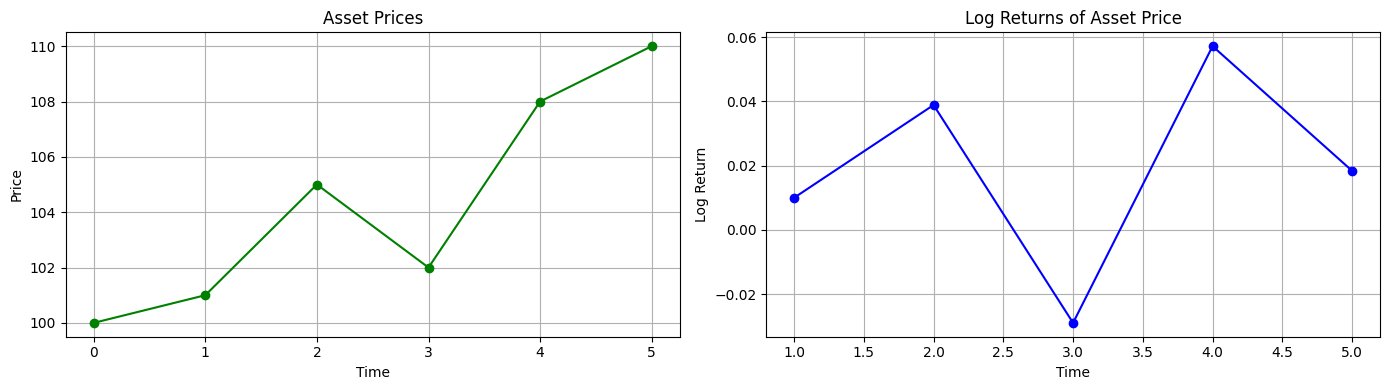

In [2]:
# Example price data (you can replace this with your own)
prices = np.array([100, 101, 105, 102, 108, 110], dtype=float)

# Compute log returns: ln(P_t / P_{t-1})
log_returns = np.log(prices[1:] / prices[:-1])

# Plot prices and log returns side by side
fig, axes = plt.subplots(1, 2, figsize=(14, 4))

# Plot original prices
axes[0].plot(range(len(prices)), prices, marker='o', linestyle='-', color='g')
axes[0].set_title("Asset Prices")
axes[0].set_xlabel("Time")
axes[0].set_ylabel("Price")
axes[0].grid(True)

# Plot log returns
axes[1].plot(range(1, len(prices)), log_returns, marker='o', linestyle='-', color='b')
axes[1].set_title("Log Returns of Asset Price")
axes[1].set_xlabel("Time")
axes[1].set_ylabel("Log Return")
axes[1].grid(True)

plt.tight_layout()
plt.show()

In [3]:
random_price = np.random.choice([-1, 1], size=400)
prod = torch.cumsum(torch.tensor(random_price), dim = 0)

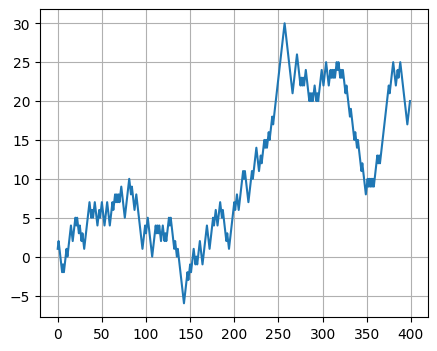

In [13]:
random_price = np.random.choice([-1, 1], size=400)
prod = torch.cumsum(torch.tensor(random_price), dim = 0)

plt.figure(figsize=(5, 4))
plt.plot(prod.numpy())
plt.grid(True)

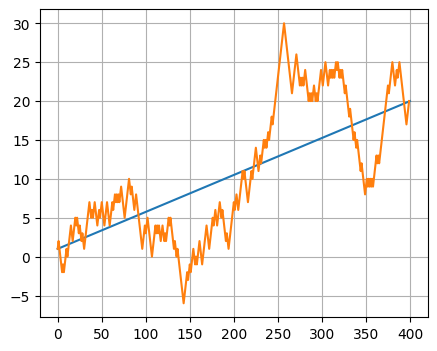

In [18]:
coor = [(0, prod[0].item()), (len(prod), prod[-1].item())]

x, y = zip(*coor)

plt.figure(figsize=(5, 4))
plt.plot(x, y)
plt.plot(prod.numpy())
plt.grid(True)


In [37]:
# This is one correct way to calculate the mean of the series using pandas
prod.float().mean()

tensor(10.7100)

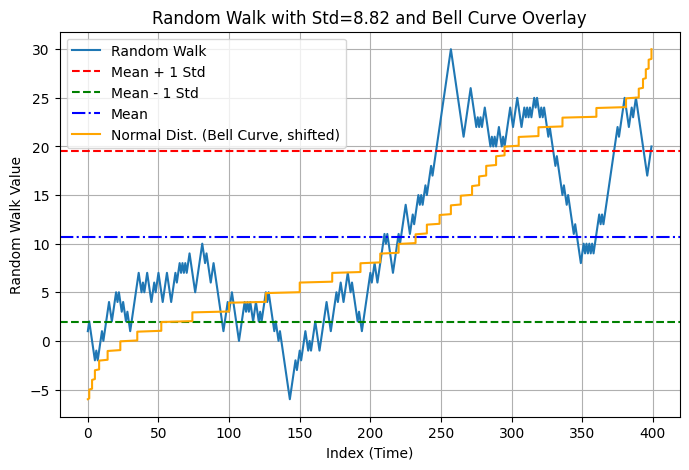

Standard deviation (manual): tensor(8.8159)
Standard deviation (torch): tensor(8.8159)


In [63]:
# Calculate standard deviation
from scipy.stats import norm

prod_np = prod.numpy()

# Manual sample standard deviation so it matches torch.std()
temp = torch.tensor(0.0)
mean_t = prod.float().mean()
for i in range(len(prod)):
    temp += (prod[i].float() - mean_t) ** 2
std_dev_t = torch.sqrt(temp / (len(prod) - 1))

mean = mean_t.item()
std_dev = std_dev_t.item()
indices = np.arange(len(prod_np))

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Left: the random walk as a time series
axes[0].plot(indices, prod_np, color="steelblue", label="Random Walk")
axes[0].axhline(mean, color="black", linestyle="-.", label="Mean")
axes[0].axhline(mean + std_dev, color="red", linestyle="--", label="Mean + 1 Std")
axes[0].axhline(mean - std_dev, color="green", linestyle="--", label="Mean - 1 Std")
axes[0].set_title("Random Walk Over Time")
axes[0].set_xlabel("Index (Time)")
axes[0].set_ylabel("Random Walk Value")
axes[0].grid(True)
axes[0].legend()

# Right: how often each value appears, with a normal curve on top
axes[1].hist(prod_np, bins=25, density=True, alpha=0.65, color="skyblue", edgecolor="black", label="Observed Frequency")
x_bell = np.linspace(prod_np.min(), prod_np.max(), 400)
axes[1].plot(x_bell, norm.pdf(x_bell, loc=mean, scale=std_dev), color="orange", linewidth=2, label="Normal Curve")
axes[1].set_title("Distribution of Random Walk Values")
axes[1].set_xlabel("Random Walk Value")
axes[1].set_ylabel("Density")
axes[1].grid(True)
axes[1].legend()

plt.tight_layout()
plt.show()

print("Mean:", mean_t)
print("Standard deviation (manual):", std_dev_t)
print("Standard deviation (torch):", prod.float().std())